# 测试：有无 z_sem 的去噪 loss 差 D(t)

**目的**：验证指标假设 —— 如果"某时间步 t 处 UNet 越依赖 z_sem，去掉它 loss 涨得越多"成立，
则 D(t) = L(无 z_sem) − L(有 z_sem) 应该有结构。

**预期形状**（假设的三个组成部分）：
- t 小：x_t 本身信息足，UNet 不需要 z_sem → D 小
- t 中高：去噪必须靠语义信息 → D 上升
- t 极大：SNR 崩坏，条件信息注不进去 → D 可能回落（若成立则 D 呈单峰，峰在中高 t）

**三种条件**（同一个 x_t、同一个噪声，只是换 cond）：
1. `cond`：正常 z_sem
2. `zero`：零向量 —— 注意这是训练时没见过的输入（OOD），所以必须有对照
3. `mismatch`：batch 内错位的 z_sem（用别的图的语义）

**判读关键**：若 D(zero) ≈ D(mismatch)，说明差值只是"输入被扰动"的 OOD 效应，指标不成立；
若两者明显不同，说明 z_sem 的**内容**确实在被使用，指标有戏。

**两个环境前提（第 1 个代码单元格开头已处理，缺一个就会报错或找错路径）**：
1. `os.chdir(PROJECT_ROOT)` —— config 里的 data_root / work_dir 是相对路径；
2. `register_all_modules(init_default_scope=True)` —— 正常训练时 tools/train.py 会自动做，
   notebook 里直接 MODELS.build 必须手动做，否则报 `SegDataPreProcessor is not in the mmengine::model registry`。

**注意：只测模型实际训练用过的 t。** 本测试的 t 列表直接从模型的 sampler 反推：
spaced 网格（ddim100 → 100 个 t）再经 custom_timestep_sampler 过滤（若有）。
对带 custom_timestep_sampler=[100,500] 的模型，实际只有 41 个 t（100,110,...,500），
区间外的行为是外推、没有意义。想看完整谱（t 覆盖 [0,999]）请用无 custom sampler 的
baseline checkpoint 跑一遍同样的测试，两个窗口的 D(t) 还能互相对照。


In [1]:
# ============ 实验参数（config 里没有对应项，自己定）============
VAL_N         = 512   # 验证图片池大小（从里面随机抽）
SAMPLES_PER_T = 256   # 每个 t 测多少个独立的 (图, 噪声) 组合 —— 压均值曲线的方差，便宜，尽量开大
BATCH_PER_T   = 32    # 每次前向的 batch 大小（显存不够就调小，必须整除 SAMPLES_PER_T）
RUN_PANEL     = True  # 是否跑第 7 节的固定图面板热力图
DEVICE        = 'cuda'
SEED          = 0

# ============ 路径：全部绝对路径 ============
# 当前指向 customSampler（t_sampler）实验；要测 baseline 就换成 baseline 的 work_dir，
# 或反过来把这份 notebook 复制一份各跑各的。
PROJECT_ROOT = '/root/diffusion_for_represent_learning/Segmentation/mmsegmentation'
WORK_DIR    = PROJECT_ROOT + '/work_dirs/ablation_experiment/baseline_diffae_ade20k'  # 测 t_sampler 实验就换成 .../diffae_ade20k_customSampler
CONFIG_PATH = WORK_DIR + '/baseline_diffae_ade20k.py'
CKPT_PATH   = WORK_DIR + '/iter_48000.pth'   # 体检单元格会自动回退到能加载的最新 ckpt
IMG_DIR     = PROJECT_ROOT + '/data/ade/ADEChallengeData2016/images/validation'
OUT_DIR     = WORK_DIR + '/zsem_gap_test'

import os, glob
import torch
import numpy as np
import pandas as pd
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device(DEVICE)

# CONFIG_PATH 不存在时，自动用 work_dir 里 mmengine 保存的那份 config
if not os.path.exists(CONFIG_PATH):
    _pys = sorted(glob.glob(os.path.join(WORK_DIR, '*.py')))
    assert _pys, f'{WORK_DIR} 里没有 .py config，手动填 CONFIG_PATH'
    CONFIG_PATH = _pys[0]
    print('auto-resolved config:', CONFIG_PATH)
print('device:', device)


auto-resolved config: /root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/baseline_diffae_ade20k/fcn_r50-d8_4xb4-80k_ade20k-512x512_diffae_pcgrad.py
device: cuda


## 0. checkpoint 体检（自动挑一个能加载的）

逐个尝试加载 checkpoint 目录（含 `resume_ckpts/`）里的所有 `.pth`，打印大小和 OK/FAIL。
如果 `CKPT_PATH` 指定的文件损坏（如保存时磁盘写满导致截断，会报 UnpicklingError），
自动改用**最新的可加载**的 checkpoint。


In [2]:
ckpt_dir = os.path.dirname(CKPT_PATH)
candidates = []
for d in [ckpt_dir, os.path.join(ckpt_dir, 'resume_ckpts')]:
    candidates += sorted(glob.glob(os.path.join(d, '*.pth')))
assert candidates, f'{ckpt_dir} 下没有任何 .pth 文件，检查路径'

print(f'找到 {len(candidates)} 个 checkpoint 候选：')
ok = []
for p in candidates:
    size_gb = os.path.getsize(p) / 1e9
    try:
        _c = torch.load(p, map_location='cpu', weights_only=False)
        _n = len(_c.get('state_dict', _c))
        print(f'  OK   {os.path.relpath(p, PROJECT_ROOT)}  {size_gb:.2f} GB  {_n} 个键')
        ok.append(p)
    except Exception as e:
        print(f'  FAIL {os.path.relpath(p, PROJECT_ROOT)}  {size_gb:.2f} GB  '
              f'{type(e).__name__}: {str(e)[:60]}')

assert ok, ('没有任何能加载的 checkpoint —— 很可能磁盘写满把文件截断了（你之前遇到过存储爆炸）。\n'
            '要么用更早实验的 checkpoint，要么从损坏的训练里另存。')
if CKPT_PATH not in ok:
    print(f'原 CKPT_PATH 不在可加载列表里：{CKPT_PATH}')
ok.sort(key=os.path.getmtime)          # 按修改时间排序，取最新
# CKPT_PATH = ok[-1]
print('最终使用:', CKPT_PATH)


找到 3 个 checkpoint 候选：
  OK   work_dirs/ablation_experiment/baseline_diffae_ade20k/iter_48000.pth  0.68 GB  867 个键
  OK   work_dirs/ablation_experiment/baseline_diffae_ade20k/iter_64000.pth  0.68 GB  867 个键
  OK   work_dirs/ablation_experiment/baseline_diffae_ade20k/iter_80000.pth  0.69 GB  867 个键
最终使用: /root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/baseline_diffae_ade20k/iter_48000.pth


## 1. 加载模型（全部参数取自 config，UNet 用 EMA 权重）

模型由 `cfg.model` 构建 —— channel_mult=(1,1,2,3)、num_res_blocks=1、image_size=128 等
一切以 config 为准，不要从模型类默认值抄。EMA 权重与推理/重建路径保持一致。


In [3]:
import os
# notebook 放哪都行：先切到项目根目录（config 里的 data_root / work_dir / IMG_DIR 都是相对路径）
PROJECT_ROOT = '/root/diffusion_for_represent_learning/Segmentation/mmsegmentation'
os.chdir(PROJECT_ROOT)

# 关键修复：注册 mmseg 的全部模块。
# 正常训练走 tools/train.py 时会自动做这一步；notebook 里手动 MODELS.build 必须自己做，
# 否则 SegDataPreProcessor 等 mmseg 组件不在注册表里，报 KeyError。
from mmseg.utils import register_all_modules
register_all_modules(init_default_scope=True)

from mmengine.config import Config
from mmseg.registry import MODELS

cfg = Config.fromfile(CONFIG_PATH)

# ---- 预处理参数取自 config；路径已在第一个单元格绝对化 ----
assert os.path.exists(CKPT_PATH), (
    f'CKPT_PATH 不存在：{CKPT_PATH}\n'
    f'用 ls 看一下目录里实际的 .pth 文件名，改第一个单元格的 CKPT_PATH'
)
print('ckpt       :', CKPT_PATH)
MEAN     = torch.tensor(cfg.data_preprocessor.mean, device=device).view(1, 3, 1, 1)
STD      = torch.tensor(cfg.data_preprocessor.std,  device=device).view(1, 3, 1, 1)
IMG_SIZE = int(cfg.model.image_size)

os.makedirs(OUT_DIR, exist_ok=True)
print('val images :', IMG_DIR)
print('out        :', OUT_DIR)
print(f'image_size={IMG_SIZE} | beta_schedule={cfg.model.beta_schedule} | '
      f'spaced={cfg.model.spaced_timesteps} | cond_dim={cfg.model.cond_dim} | '
      f'num_diffusion_timesteps={cfg.model.num_diffusion_timesteps}')

model = MODELS.build(cfg.model)

ckpt = torch.load(CKPT_PATH, map_location='cpu', weights_only=False)
state = ckpt['state_dict'] if 'state_dict' in ckpt else ckpt
state = {k.replace('module.', ''): v for k, v in state.items()}
model.load_state_dict(state, strict=False)

model.to(device).eval()
for p in model.parameters():
    p.requires_grad_(False)

# EMA 权重覆盖到 UNet / 压缩层上
model.ema.apply_shadow()

T = model.sampler.num_timesteps  # 1000（logSNR 数组按这个长度算）

# 本模型实际训练用过的 t 集合：spaced 网格（ddim100 -> 100 个）再经 custom_timestep_sampler 过滤
if model.sampler.use_custom_timestep_sampler:
    T_LIST = [model.sampler.use_timesteps[i] for i in model.sampler.custom_timestep_indices]
else:
    T_LIST = list(model.sampler.use_timesteps)
print(f'实际训练用过的 t：共 {len(T_LIST)} 个，范围 [{min(T_LIST)}, {max(T_LIST)}]')
print('前 10 个:', T_LIST[:10])


ckpt       : /root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/baseline_diffae_ade20k/iter_48000.pth
val images : /root/diffusion_for_represent_learning/Segmentation/mmsegmentation/data/ade/ADEChallengeData2016/images/validation
out        : /root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/baseline_diffae_ade20k/zsem_gap_test
image_size=128 | beta_schedule=linear | spaced=ddim100 | cond_dim=512 | num_diffusion_timesteps=1000


/root/diffusion_for_represent_learning/Segmentation/mmsegmentation/mmseg/models/backbones/resnet.py:431: UserWarning: DeprecationWarning: pretrained is a deprecated, please use "init_cfg" instead
  warnings.warn('DeprecationWarning: pretrained is a deprecated, '
/root/diffusion_for_represent_learning/Segmentation/mmsegmentation/mmseg/models/losses/cross_entropy_loss.py:250: UserWarning: Default ``avg_non_ignore`` is False, if you would like to ignore the certain label and average loss over non-ignore labels, which is the same with PyTorch official cross_entropy, set ``avg_non_ignore=True``.
  warnings.warn(


实际训练用过的 t：共 101 个，范围 [0, 999]
前 10 个: [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]


## 2. 准备验证图片池

复刻 `loss()` 里扩散分支看到的输入：
- `pool_norm`：ImageNet 标准化后的图（mean/std 取自 config），给 backbone 提 z_sem 用
- `pool01 * 2 - 1`：映射到 [-1, 1] 的图，给扩散过程用

注意 config 里 crop_size=(512,512) 只作用于分割分支；扩散分支在 `_to_diffae_range`
里内部缩放到 image_size=128，所以这里直接缩放到 128，和训练时 UNet 看到的输入一致。


In [4]:
from PIL import Image

paths = sorted(glob.glob(os.path.join(IMG_DIR, '*.jpg')))[:VAL_N]
assert len(paths) > 0, f'在 {IMG_DIR} 没找到图片，检查路径'

imgs = []
for p in paths:
    im = Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(im)).permute(2, 0, 1).float() / 255.0  # [3,H,W], [0,1]
    imgs.append(x)

pool01    = torch.stack(imgs).to(device)                    # [N,3,H,W]
pool_norm = (pool01 * 255.0 - MEAN) / STD                   # backbone 输入
print('图片池:', pool01.shape)

@torch.no_grad()
def get_cond(x_norm):
    '''复刻 loss() 里的 z_sem 路径：backbone -> 平均池化 -> 压缩层 -> [B,cond_dim]'''
    feats = model.backbone(x_norm)
    z = torch.nn.functional.adaptive_avg_pool2d(feats[-1], 1).flatten(1)
    return model.diffae_enc_compress(z)


/tmp/ipykernel_910457/3486629407.py:9: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  x = torch.from_numpy(np.asarray(im)).permute(2, 0, 1).float() / 255.0  # [3,H,W], [0,1]


图片池: torch.Size([512, 3, 128, 128])


## 3. 主循环：遍历全部 t，记录三种条件下的 per-sample loss

流程确认：外层遍历 T_LIST（模型实际训练用过的 t，见第 1 节）；每个 t 从图池里**有放回**随机抽 SAMPLES_PER_T 张
（不同 t 重复抽到同一张图是有意的，曲线反映的是 t 而不是某几张图）；每张图新鲜采一份
噪声加噪成 x_t，然后**同一个 x_t** 分别用 正常z_sem / 零向量 / 错位z_sem 前向。

三组 loss 严格配对（同图、同噪声、同 t），唯一变量是 cond，
所以差值 D 不受图片难度和噪声抽样的干扰。


In [5]:
from tqdm import tqdm

assert SAMPLES_PER_T % BATCH_PER_T == 0, 'BATCH_PER_T 必须整除 SAMPLES_PER_T'
rounds = SAMPLES_PER_T // BATCH_PER_T

recs = []
for t_val in tqdm(T_LIST, desc='scan t'):
    t = torch.full((BATCH_PER_T,), t_val, device=device, dtype=torch.long)
    for _ in range(rounds):                      # 每轮：BATCH_PER_T 张不同的随机图 + 独立噪声
        idx = torch.randint(0, pool01.shape[0], (BATCH_PER_T,), device=device)

        x0    = pool01[idx] * 2.0 - 1.0          # [-1,1]
        cond  = get_cond(pool_norm[idx])         # 正常 z_sem
        noise = torch.randn_like(x0)
        x_t   = model.sampler.q_sample(x0, t, noise)

        with torch.no_grad():
            pred_c = model.diffae_unet(x_t, t, cond)                       # 有 z_sem
            pred_z = model.diffae_unet(x_t, t, torch.zeros_like(cond))     # 零向量
            pred_m = model.diffae_unet(x_t, t, cond.roll(1, 0))            # 错位 z_sem

        l_cond = (pred_c - noise).pow(2).flatten(1).mean(1)
        l_zero = (pred_z - noise).pow(2).flatten(1).mean(1)
        l_mis  = (pred_m - noise).pow(2).flatten(1).mean(1)

        for i in range(BATCH_PER_T):
            recs.append(dict(
                t=t_val, img=idx[i].item(),
                l_cond=l_cond[i].item(), l_zero=l_zero[i].item(), l_mis=l_mis[i].item(),
            ))

df = pd.DataFrame(recs)
df['d_zero'] = df.l_zero - df.l_cond   # 去掉 z_sem 的 loss 涨幅
df['d_mis']  = df.l_mis  - df.l_cond   # 换成错误 z_sem 的 loss 涨幅
df.to_csv(os.path.join(OUT_DIR, 'per_sample.csv'), index=False)
print(df.shape, f'= {len(T_LIST)} 个 t x {SAMPLES_PER_T} 个独立采样')


scan t: 100%|██████████| 101/101 [06:34<00:00,  3.91s/it]


(25856, 7) = 101 个 t x 256 个独立采样


## 4. 按 t 聚合 + logSNR

logSNR = log(ᾱ_t / (1−ᾱ_t))，即加噪公式 x_t = √ᾱ·x₀ + √(1−ᾱ)·ε 里的信噪比取对数。
t 只是下标，真正的"噪声量"由 ᾱ 决定且随 t 非线性变化，所以同一曲线画两种横轴：
t（下标）和 logSNR（实际噪声量，换 beta 方案/换时间步数后依然可比，峰的位置要按它报）。
聚合同时给均值和中位数（per-sample 差值是重尾分布，中位数抗离群值）。


In [6]:
ab = model.sampler.alphas_cumprod.detach().cpu().numpy()
logsnr = np.log(ab / (1.0 - ab))          # [T]
df['logsnr'] = logsnr[df['t'].values]

g = df.groupby('t').agg(
    l_cond_mean=('l_cond', 'mean'), l_zero_mean=('l_zero', 'mean'), l_mis_mean=('l_mis', 'mean'),
    d_zero_mean=('d_zero', 'mean'), d_zero_med=('d_zero', 'median'), d_zero_std=('d_zero', 'std'),
    d_mis_mean=('d_mis', 'mean'), d_mis_med=('d_mis', 'median'),
    frac_pos=('d_zero', lambda s: (s > 0).mean()),
).reset_index()
g['logsnr'] = logsnr[g['t'].values]
g.to_csv(os.path.join(OUT_DIR, 'per_t_agg.csv'), index=False)
g.head(3)


,t,l_cond_mean,l_zero_mean,l_mis_mean,d_zero_mean,d_zero_med,d_zero_std,d_mis_mean,d_mis_med,frac_pos,logsnr
0,0,0.536479,0.536492,0.536479,0.000013,0.000021,0.000043,5.871989e-07,3.576279e-07,0.691406,9.210074
1,10,0.243854,0.243875,0.243855,0.000021,0.000023,0.000026,4.260510e-07,3.352761e-07,0.851562,6.120083
2,20,0.172277,0.172295,0.172277,0.000017,0.000020,0.000017,2.840534e-08,6.705523e-08,0.871094,5.066533


## 4.5 数值体检：确认"三条曲线重合"是比例尺问题还是真没区别

fig1 的 y 轴是 0~0.5，D 若只有 1e-3 量级会看起来完美重合——必须用数字判断。
本单元格输出 6 项检查：
1. 三种条件的预测是否真的不同（max abs diff ≈ 0 = UNet 完全无视 cond）
2. z_sem 跨样本方差（≈0 = encoder 输出常量，z_sem 本身没有信息量）
3. cond 注入层权重范数（全 0 / 极小 = 结构上就没学用 cond）
4. EMA 是否生效（当前权重应和 checkpoint 里的非 EMA 权重不同）
5. BN 模式差异（训练时 BN 用 batch 统计量，eval 用 running stats，z_sem 分布会偏移）
6. 当前使用的 checkpoint 路径

判读：
- 检查 1 ≈ 0 且检查 3 权重 ≈ 0 -> UNet 真没用 z_sem（训练不充分/捷径），指标在这个模型上无信号，
  这本身就是结论：∂ε/∂z_sem≈0，encoder 通过 cond 拿到的梯度≈0，可解释 diffae 分支为何没增益。
- 检查 1 有可观数值但 fig1 看不见 -> 纯比例尺问题，去看 fig2 和 per_t_agg.csv 的数字。


In [7]:
torch.manual_seed(123)
t_fix = torch.full((8,), 500, device=device, dtype=torch.long)   # 中高噪声区
idx_fix = torch.randint(0, pool01.shape[0], (8,), device=device)
x0_f    = pool01[idx_fix] * 2.0 - 1.0
cond_f  = get_cond(pool_norm[idx_fix])
noise_f = torch.randn_like(x0_f)
x_t_f   = model.sampler.q_sample(x0_f, t_fix, noise_f)

with torch.no_grad():
    p_c = model.diffae_unet(x_t_f, t_fix, cond_f)
    p_z = model.diffae_unet(x_t_f, t_fix, torch.zeros_like(cond_f))
    p_m = model.diffae_unet(x_t_f, t_fix, cond_f.roll(1, 0))

print('1) 三种条件的预测差异（max abs diff）:')
print('   |pred(zero) - pred(cond)| =', (p_z - p_c).abs().max().item())
print('   |pred(mis)  - pred(cond)| =', (p_m - p_c).abs().max().item())

print('2) z_sem 跨样本变化幅度:')
print('   per-dim std       =', cond_f.std(0).mean().item())
print('   per-dim |mean|    =', cond_f.mean(0).abs().mean().item())

print('3) cond 注入层权重范数（第一个 resblock 的）:')
for n, m in model.diffae_unet.named_modules():
    if hasattr(m, 'cond_emb_proj'):
        w = m.cond_emb_proj[-1].weight
        print(f'   {n}: |W| mean={w.abs().mean().item():.6f}  max={w.abs().max().item():.6f}')
        break

print('4) EMA 是否生效（当前[EMA] vs checkpoint[非EMA]，应不同）:')
_sd = ckpt['state_dict'] if 'state_dict' in ckpt else ckpt
_k = 'diffae_unet.mid_block1.cond_emb_proj.1.weight'
if _k in _sd:
    print('   ckpt  前5个:', [round(v, 5) for v in _sd[_k].flatten()[:5].tolist()])
    print('   当前  前5个:', [round(v, 5) for v in model.diffae_unet.mid_block1.cond_emb_proj[1].weight.flatten()[:5].tolist()])
else:
    print('   ckpt 键名不匹配，跳过（不影响，前 3 项才是核心）')

print('5) BN 模式对 z_sem 的影响:')
model.backbone.train()
cond_f_trainbn = get_cond(pool_norm[idx_fix])
model.backbone.eval()
print('   相对差 =', ((cond_f_trainbn - cond_f).norm() / cond_f.norm().clamp_min(1e-8)).item())

print('6) 当前 checkpoint:', CKPT_PATH)


1) 三种条件的预测差异（max abs diff）:
   |pred(zero) - pred(cond)| = 0.0005409717559814453
   |pred(mis)  - pred(cond)| = 0.00016367435455322266
2) z_sem 跨样本变化幅度:
   per-dim std       = 0.0002654404961504042
   per-dim |mean|    = 0.003877386450767517
3) cond 注入层权重范数（第一个 resblock 的）:
   down_blocks.0: |W| mean=0.003871  max=0.007772
4) EMA 是否生效（当前[EMA] vs checkpoint[非EMA]，应不同）:
   ckpt  前5个: [-0.00599, -0.00083, -0.00212, 0.00728, -0.00228]
   当前  前5个: [-0.00599, -0.00083, -0.00212, 0.00728, -0.00228]
5) BN 模式对 z_sem 的影响:
   相对差 = 0.05870528146624565
6) 当前 checkpoint: /root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/baseline_diffae_ade20k/iter_48000.pth


## 5. 图 1 & 2：loss 曲线与 D(t) 曲线


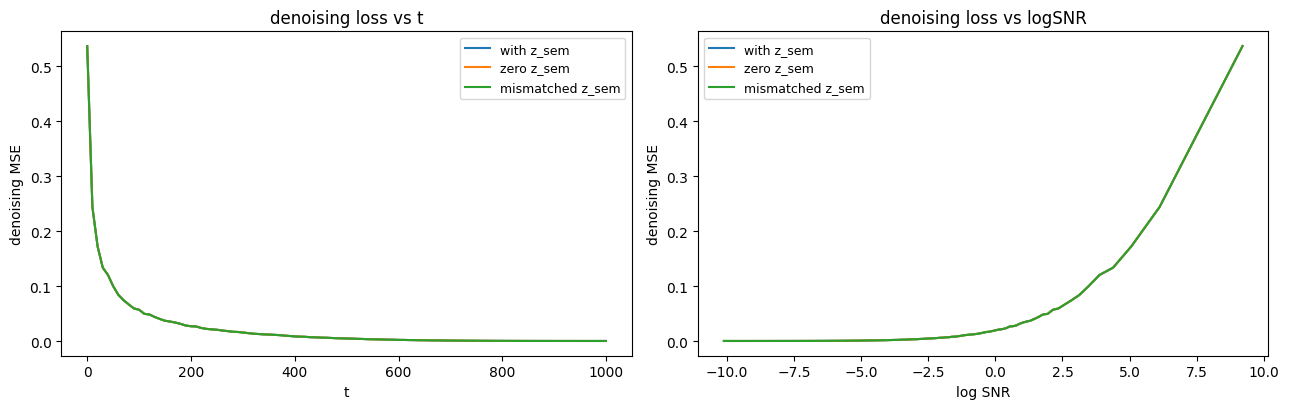

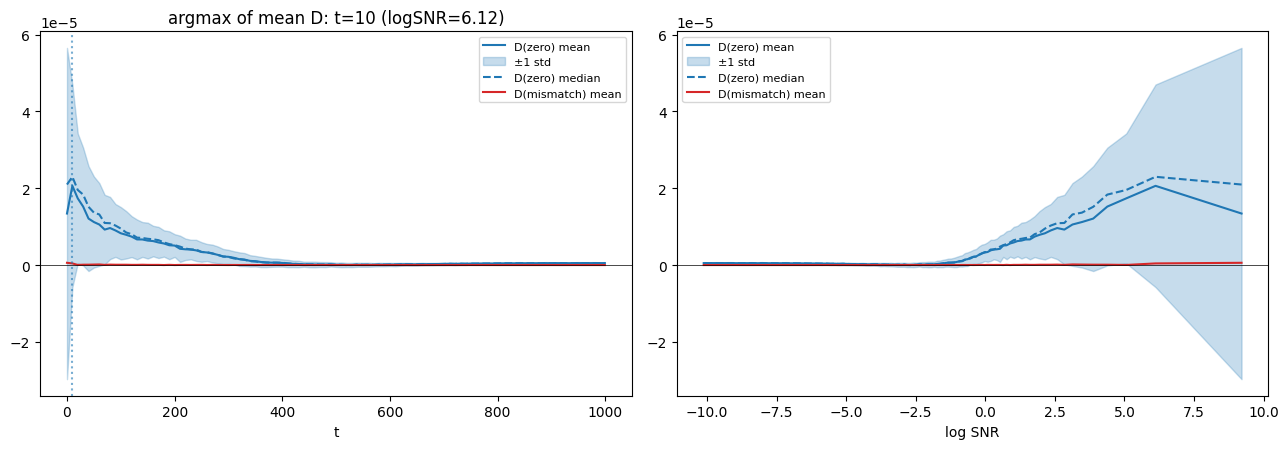

In [8]:
import matplotlib.pyplot as plt

# ---- 图1：三种条件下的去噪 loss 曲线 ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, xcol, xlab in [(axes[0], 't', 't'), (axes[1], 'logsnr', 'log SNR')]:
    ax.plot(g[xcol], g.l_cond_mean, label='with z_sem')
    ax.plot(g[xcol], g.l_zero_mean, label='zero z_sem')
    ax.plot(g[xcol], g.l_mis_mean,  label='mismatched z_sem')
    ax.set_xlabel(xlab); ax.set_ylabel('denoising MSE'); ax.legend(fontsize=9)
axes[0].set_title('denoising loss vs t'); axes[1].set_title('denoising loss vs logSNR')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'fig1_loss_curves.png'), dpi=200); plt.show()

# ---- 图2：D(t) 曲线（左横轴 t，右横轴 logSNR）----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, xcol, xlab in [(axes[0], 't', 't'), (axes[1], 'logsnr', 'log SNR')]:
    ax.plot(g[xcol], g.d_zero_mean, color='C0', label='D(zero) mean')
    ax.fill_between(g[xcol], g.d_zero_mean - g.d_zero_std, g.d_zero_mean + g.d_zero_std,
                    color='C0', alpha=0.25, label='±1 std')
    ax.plot(g[xcol], g.d_zero_med,  color='C0', ls='--', label='D(zero) median')
    ax.plot(g[xcol], g.d_mis_mean,  color='C3', label='D(mismatch) mean')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel(xlab); ax.legend(fontsize=8)
i_max = g.d_zero_mean.values.argmax()
axes[0].axvline(g.t[i_max], color='C0', ls=':', alpha=0.6)
axes[0].set_title(f'argmax of mean D: t={g.t[i_max]} (logSNR={g.logsnr[i_max]:.2f})')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'fig2_D_curves.png'), dpi=200); plt.show()


## 6. 图 3：样本级散点（看方差）+ 混淆检查

D 与 L_cond 的相关性是一个重要混淆：如果两者高度相关，说明"差距"很大程度
反映的是图片本身的难度（难图 loss 高、差距也大），而不是 t 的粒度效应。


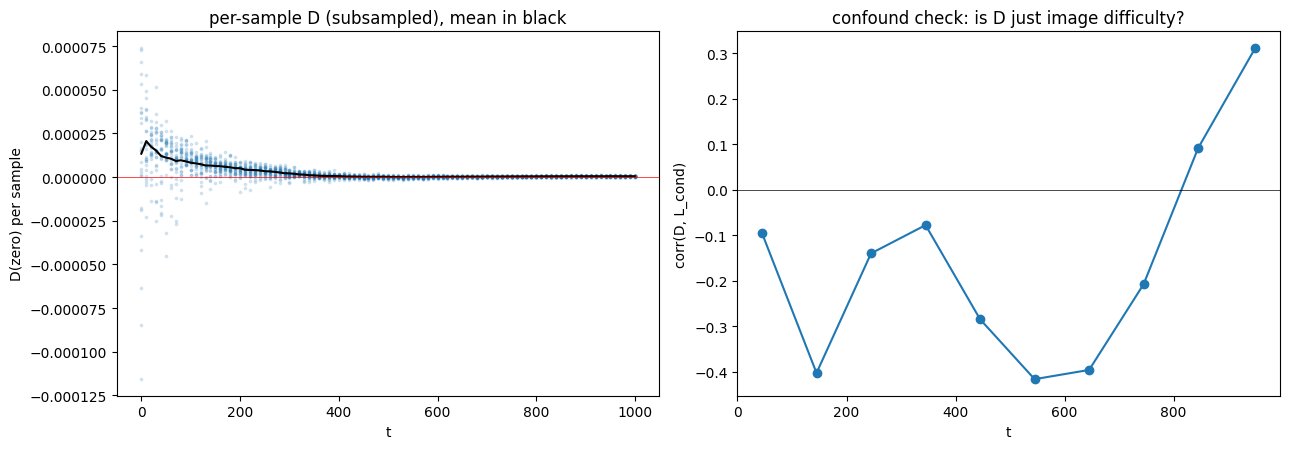

In [9]:
# ---- 图3：左：样本散点；右：corr(D, L_cond) 随 t 的变化 ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

sub = df.iloc[::10]  # 每10条抽1条，避免点太密
axes[0].scatter(sub.t, sub.d_zero, s=3, alpha=0.15, color='C0')
axes[0].plot(g.t, g.d_zero_mean, color='k', lw=1.5)
axes[0].axhline(0, color='r', lw=0.5)
axes[0].set_xlabel('t'); axes[0].set_ylabel('D(zero) per sample')
axes[0].set_title('per-sample D (subsampled), mean in black')

df['t_seg'] = pd.cut(df.t, 10)
grp = df.groupby('t_seg', observed=True)
corr = grp.apply(lambda s: s.d_zero.corr(s.l_cond), include_groups=False)
mid  = grp.t.mean()
axes[1].plot(mid, corr, marker='o')
axes[1].set_xlabel('t'); axes[1].set_ylabel('corr(D, L_cond)')
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_title('confound check: is D just image difficulty?')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'fig3_scatter_confound.png'), dpi=200); plt.show()


## 7. 图 4（可选）：固定 32 张图 × 全部 t 的热力图

回答"峰的形状是稳定的还是个别图撑起来的"。行 = 图片（按平均 D 排序），列 = t，颜色 = D。
如果每行都在差不多的 t 位置出现同样的模式，说明 D(t) 是稳定的图像级现象。


panel:   0%|          | 0/101 [00:00<?, ?it/s]

panel: 100%|██████████| 101/101 [02:05<00:00,  1.24s/it]


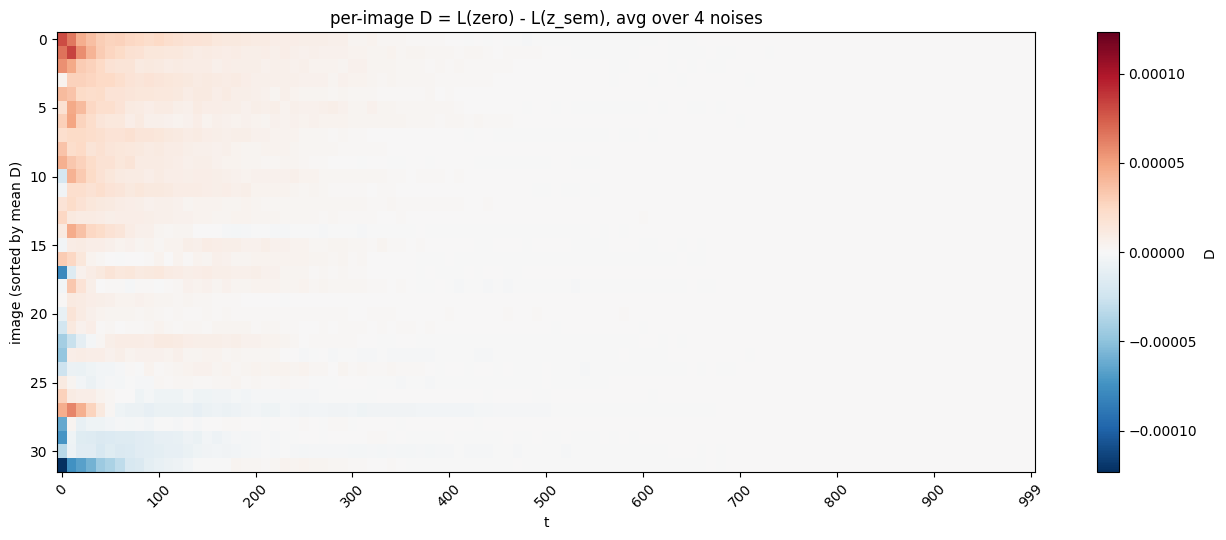

In [10]:
if RUN_PANEL:
    PANEL_N       = 32
    PANEL_REPEATS = 4     # 每个 (图, t) 用几份噪声平均，格子颜色才稳
    idx_p  = torch.arange(PANEL_N, device=device)
    x0_p   = pool01[idx_p] * 2.0 - 1.0
    cond_p = get_cond(pool_norm[idx_p])

    rows = []
    for t_val in tqdm(T_LIST, desc='panel'):
        t   = torch.full((PANEL_N,), t_val, device=device, dtype=torch.long)
        acc_d, acc_lc = torch.zeros(PANEL_N, device=device), torch.zeros(PANEL_N, device=device)
        for _ in range(PANEL_REPEATS):
            noise = torch.randn_like(x0_p)
            x_t = model.sampler.q_sample(x0_p, t, noise)
            with torch.no_grad():
                pc_ = model.diffae_unet(x_t, t, cond_p)
                pz_ = model.diffae_unet(x_t, t, torch.zeros_like(cond_p))
            lc = (pc_ - noise).pow(2).flatten(1).mean(1)
            lz = (pz_ - noise).pow(2).flatten(1).mean(1)
            acc_d  += lz - lc
            acc_lc += lc
        d_mean  = (acc_d  / PANEL_REPEATS).cpu()
        lc_mean = (acc_lc / PANEL_REPEATS).cpu()
        for i in range(PANEL_N):
            rows.append(dict(img=i, t=t_val, l_cond=lc_mean[i].item(), d_zero=d_mean[i].item()))

    panel = pd.DataFrame(rows)
    panel.to_csv(os.path.join(OUT_DIR, 'panel_per_image.csv'), index=False)

    piv = panel.pivot(index='img', columns='t', values='d_zero')
    piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(13, 5.5))
    v = np.nanmax(np.abs(piv.values))
    im = ax.imshow(piv.values, aspect='auto', cmap='RdBu_r', vmin=-v, vmax=v)
    step = max(1, len(piv.columns) // 10)
    ax.set_xticks(np.arange(0, len(piv.columns), step))
    ax.set_xticklabels(list(piv.columns)[::step], rotation=45)
    ax.set_xlabel('t'); ax.set_ylabel('image (sorted by mean D)')
    ax.set_title(f'per-image D = L(zero) - L(z_sem), avg over {PANEL_REPEATS} noises')
    fig.colorbar(im, ax=ax, label='D')
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'fig4_heatmap.png'), dpi=200); plt.show()


## 8. 汇总输出（怎么读）


In [11]:
print('=== 汇总 ===')
print(f"L_cond 全体均值: {df.l_cond.mean():.4f}   （对照训练日志里 diffae loss 稳态 ~0.02-0.03，差太远说明模型没加载对）")
print(f"D(zero)>0 的样本比例: {(df.d_zero > 0).mean():.3f}   （应该接近 1：去掉条件不可能更好）")
print(f'D 的绝对量级: mean|d_zero|={df.d_zero.abs().mean():.6f}  vs  mean L_cond={df.l_cond.mean():.4f}')
print()
i  = g.d_zero_mean.values.argmax()
im = g.d_zero_med.values.argmax()
print(f"D(zero) 均值峰值:   t={g.t[i]:4d}  logSNR={g.logsnr[i]:6.2f}  D={g.d_zero_mean[i]:.4f}")
print(f"D(zero) 中位数峰值: t={g.t[im]:4d}  logSNR={g.logsnr[im]:6.2f}")
j = g.d_mis_mean.values.argmax()
print(f"D(mis)  均值峰值:   t={g.t[j]:4d}  logSNR={g.logsnr[j]:6.2f}  D={g.d_mis_mean[j]:.4f}")
print()
print('按 logSNR 四等分的 D(zero) 均值（看随噪声量的趋势）:')
print(g.assign(snr_bin=pd.qcut(g.logsnr, 4)).groupby('snr_bin', observed=True).d_zero_mean.mean().round(4))
print()
print('三个判定:')
print(' 1) D 有单峰且 D(mis) 与 D(zero) 明显不同  -> 指标成立, 峰 = 最依赖 z_sem 的粒度')
print(' 2) D(zero) ≈ D(mis)                       -> 只是 OOD 扰动效应, 指标不成立')
print(' 3) corr(D, L_cond) 全程 > 0.8             -> 差距主要是图片难度, 指标需要再处理')


=== 汇总 ===
L_cond 全体均值: 0.0244   （对照训练日志里 diffae loss 稳态 ~0.02-0.03，差太远说明模型没加载对）
D(zero)>0 的样本比例: 0.828   （应该接近 1：去掉条件不可能更好）
D 的绝对量级: mean|d_zero|=0.000003  vs  mean L_cond=0.0244

D(zero) 均值峰值:   t=  10  logSNR=  6.12  D=0.0000
D(zero) 中位数峰值: t=  10  logSNR=  6.12
D(mis)  均值峰值:   t=   0  logSNR=  9.21  D=0.0000

按 logSNR 四等分的 D(zero) 均值（看随噪声量的趋势）:
snr_bin
(-10.119, -5.71]    0.0
(-5.71, -2.473]     0.0
(-2.473, 0.0857]    0.0
(0.0857, 9.21]      0.0
Name: d_zero_mean, dtype: float64

三个判定:
 1) D 有单峰且 D(mis) 与 D(zero) 明显不同  -> 指标成立, 峰 = 最依赖 z_sem 的粒度
 2) D(zero) ≈ D(mis)                       -> 只是 OOD 扰动效应, 指标不成立
 3) corr(D, L_cond) 全程 > 0.8             -> 差距主要是图片难度, 指标需要再处理


In [12]:
# 收尾：恢复非 EMA 参数（如果之后还要在这个 session 里继续训练）
model.ema.restore()
print('done. outputs in', OUT_DIR)


done. outputs in /root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/baseline_diffae_ade20k/zsem_gap_test
